In [1]:
import os, sys
#os.chdir("/home/isae/a.brun/Documents/Codes/NeuralNetworks")
#sys.path.insert(0, os.getcwd())

In [2]:
from test import *
from tools import *
import visualtorch

In [3]:
crits

MSE
L1
SmoothL1
SoftMarginLoss
Huber
CrossEntropy
KLDiv
PoissonNLL
MultiLabelSoftMargin

In [4]:
img = Image.open("/home/daep/a.brun/Téléchargements/image.jpg") #local
#img = Image.open("/home/isae/a.brun/image.jpg") #MODUS
#Pando


In [5]:
shape = np.array(img).shape[:-1]

X , Y = np.meshgrid(np.linspace(0,1,shape[1]),np.linspace(0,1,shape[0]))

inputs = torch.stack((torch.tensor(X),torch.tensor(Y)),dim=-1).reshape(-1,2)

outputs = torch.tensor(np.array(img)).reshape(-1,3)/256


inputs = inputs.to(dtype=torch.float32)
outputs = outputs.to(dtype=torch.float32)


In [8]:
trainer = Trainer(net,
                  inputs = inputs, outputs = outputs,
                  init_train_size = 1.0,final_train_size = 1.0,
                  crit="MSE",
                  optim="Adam",
                  init_lr=1e-3,
                  final_lr=1e-5,
                  batch_size = 1024*320)

In [9]:
trainer.train(100)

Training Net:   0%|          | 0/100 [00:00<?, ?epoch/s]

In [10]:
res = net(inputs).reshape(350,525,3).clamp_(0,1.0).mul_(256).numpy().astype(np.uint8)
ref = outputs.reshape(350,525,3).clamp_(0.0,1.0).mul_(256).numpy().astype(np.uint8)
img_ia =Image.fromarray(res)
img_diff =Image.fromarray(res-ref)


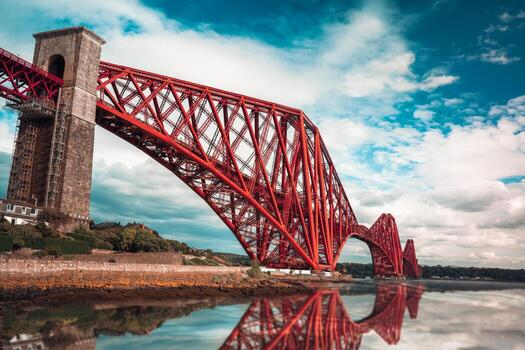

In [11]:
img

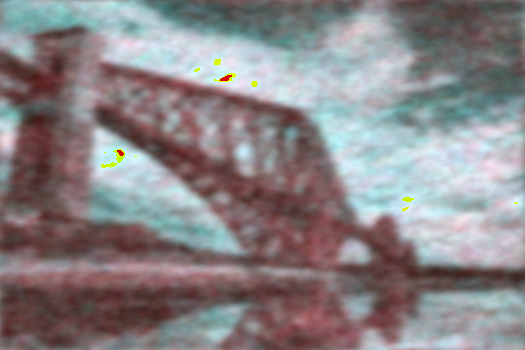

In [12]:
img_ia

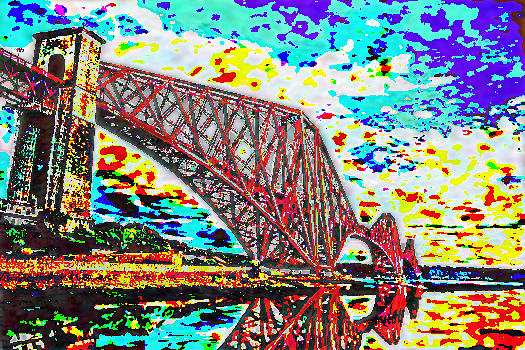

In [13]:
img_diff

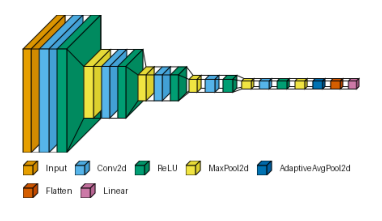

In [50]:
img = visualtorch.render(net2.model, input_shape=(1,3,128,128), style="flow", legend=True)
import matplotlib.pyplot as plt
dpi = 150  # rendered at 2x this in the final doc build (savefig.dpi=300 in conf.py)
plt.figure(figsize=(img.width / dpi, img.height / dpi), dpi=dpi)
plt.imshow(img)
plt.axis("off")
plt.tight_layout()
plt.show()

In [51]:
net2.model

Sequential(
  (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(32, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): AdaptiveAvgPool2d(output_size=(1, 1))
  (16): Flatten(start_dim=1, end_dim=-1)
  (17): Linear(in_features=128, out_features=10